# A6 - Dự đoán hành vi tiếp theo của khách hàng bằng RNN (Keras)

**Dataset:** `events.csv` - Retailrocket E-commerce Dataset  
**Framework:** TensorFlow / Keras  
**Mô hình chính:** `Embedding + SimpleRNN`  
**Bài toán:** dùng **5 hành vi gần nhất của một khách hàng** để dự đoán **hành vi tiếp theo**.

Ba nhãn hành vi:

- `view` → xem sản phẩm
- `addtocart` → thêm vào giỏ hàng
- `transaction` → giao dịch/mua hàng

Đây là bài toán **phân loại chuỗi (sequence classification)** dạng **Many-to-One**.

Notebook được tổ chức theo quy trình:

1. Load Data
2. Data Understanding
3. Cleaning
4. Visualization / EDA
5. Phân tích chuỗi hành vi khách hàng
6. Tạo sequence theo từng visitor
7. Train / Validation / Test Split theo thời gian
8. Encoding
9. Build RNN
10. Compile
11. Train
12. Plot Training / Validation
13. Predict
14. Evaluate
15. Confusion Matrix + Classification Report
16. So sánh Majority Baseline
17. Demo dự đoán một chuỗi hành vi
18. Hyperparameter Tuning (tùy chọn)
19. Kết luận

> **Quan trọng:** Không được tạo sequence xuyên qua hai `visitorid` khác nhau.  
> Mỗi sequence phải thuộc về **một khách hàng duy nhất**.

**Bản nộp độc lập:** toàn bộ hàm xử lý dữ liệu, định nghĩa mô hình, huấn luyện
và kiểm tra tải lại đều nằm trong notebook. Không cần các file `.py` của dự án.
Đặt CSV tương ứng cạnh notebook, chọn kernel đã cài thư viện và Restart & Run All.
Chọn checkpoint/cấu hình bằng Validation; Test chỉ dùng để báo cáo cuối cùng.

## 0. Import thư viện

In [1]:
# Nếu cần: %pip install numpy pandas matplotlib scikit-learn tensorflow

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set before importing a framework; helps deterministic CUDA execution.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
SEED = int(os.environ.get("RNN_SEED", "42"))
np.random.seed(SEED)
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense, Embedding
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("TensorFlow:", tf.__version__, "| Pandas:", pd.__version__, "| Seed:", SEED)

TensorFlow: 2.21.0 | Pandas: 2.3.2 | Seed: 42


## 1. Load Data

In [2]:
# Hỗ trợ CSV cạnh notebook hoặc cấu trúc data/ + notebooks/.
candidates = [Path.cwd() / "events.csv",
              Path.cwd() / "data" / "events.csv",
              Path.cwd().parent / "data" / "events.csv"]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Đặt events.csv cạnh notebook hoặc trong thư mục data/.")
PROJECT_ROOT = DATA_PATH.parent.parent if DATA_PATH.parent.name == "data" else DATA_PATH.parent
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_raw = pd.read_csv(DATA_PATH)
required_columns = ['timestamp', 'visitorid', 'itemid', 'event']
missing = set(required_columns) - set(df_raw.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
print("Data:", DATA_PATH)
print("Results:", RESULTS_DIR)
print("Shape:", df_raw.shape)
display(df_raw.head())

Data: D:\A06\data\events.csv
Results: D:\A06\results
Shape: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## 2. Data Understanding

In [3]:
print("5 dòng đầu:")
display(df_raw.head())

print("\n5 dòng cuối:")
display(df_raw.tail())

print("\nShape:", df_raw.shape)

print("\nCác cột:")
print(df_raw.columns.tolist())

print("\nThông tin dữ liệu:")
df_raw.info()

5 dòng đầu:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



5 dòng cuối:


,timestamp,visitorid,event,itemid,transactionid
2756096,1438398785939,591435,view,261427,NaN
2756097,1438399813142,762376,view,115946,NaN
2756098,1438397820527,1251746,view,78144,NaN
2756099,1438398530703,1184451,view,283392,NaN
2756100,1438400163914,199536,view,152913,NaN



Shape: (2756101, 5)

Các cột:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [4]:
print("Thống kê mô tả:")
display(df_raw.describe(include="all"))

Thống kê mô tả:


,timestamp,visitorid,event,itemid,transactionid
count,2.756101e+06,2.756101e+06,2756101,2.756101e+06,22457.000000
unique,NaN,NaN,3,NaN,NaN
top,NaN,NaN,view,NaN,NaN
freq,NaN,NaN,2664312,NaN,NaN
mean,1.436424e+12,7.019229e+05,NaN,2.349225e+05,8826.497796
std,3.366312e+09,4.056875e+05,NaN,1.341954e+05,5098.996290
min,1.430622e+12,0.000000e+00,NaN,3.000000e+00,0.000000
25%,1.433478e+12,3.505660e+05,NaN,1.181200e+05,4411.000000
50%,1.436453e+12,7.020600e+05,NaN,2.360670e+05,8813.000000
75%,1.439225e+12,1.053437e+06,NaN,3.507150e+05,13224.000000


### Ý nghĩa các cột chính

- `timestamp`: thời điểm xảy ra sự kiện.
- `visitorid`: mã khách truy cập.
- `event`: loại hành vi (`view`, `addtocart`, `transaction`).
- `itemid`: mã sản phẩm.
- `transactionid`: mã giao dịch, thường chỉ có khi `event = transaction`.

Trong bài RNN cơ bản này, ta tập trung vào **chuỗi hành vi `event` theo thời gian của từng visitor**.

## 3. Cleaning

In [5]:
df = df_raw.copy()

print("Missing values trước xử lý:")
display(df.isna().sum())

print("\nSố dòng trùng hoàn toàn:")
print(df.duplicated().sum())

# Loại bản ghi trùng hoàn toàn
df = df.drop_duplicates().copy()

# Timestamp của Retailrocket ở dạng milliseconds kể từ Unix epoch
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# Chuẩn hóa event
df["event"] = (
    df["event"]
    .astype(str)
    .str.strip()
    .str.lower()
)

valid_events = [
    "view",
    "addtocart",
    "transaction"
]

df = df[
    df["datetime"].notna()
    & df["visitorid"].notna()
    & df["event"].isin(valid_events)
].copy()

# visitorid/itemid về integer nếu có thể
df["visitorid"] = pd.to_numeric(
    df["visitorid"],
    errors="coerce"
)

df["itemid"] = pd.to_numeric(
    df["itemid"],
    errors="coerce"
)

df = df.dropna(
    subset=["visitorid", "itemid"]
).copy()

df["visitorid"] = df["visitorid"].astype("int64")
df["itemid"] = df["itemid"].astype("int64")

# Sắp xếp theo khách hàng và thời gian
df = (
    df.sort_values(
        ["visitorid", "datetime", "timestamp"]
    )
    .reset_index(drop=True)
)

print("Shape sau cleaning:", df.shape)
print("Khoảng thời gian:")
print(
    df["datetime"].min(),
    "->",
    df["datetime"].max()
)

print("\nCác loại event:")
print(df["event"].value_counts())

display(df.head())

Missing values trước xử lý:


timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64


Số dòng trùng hoàn toàn:
460
Shape sau cleaning: (2755641, 6)
Khoảng thời gian:
2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000

Các loại event:
event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1442004589439,0,view,285930,NaN,2015-09-11 20:49:49.439
1,1442004759591,0,view,357564,NaN,2015-09-11 20:52:39.591
2,1442004917175,0,view,67045,NaN,2015-09-11 20:55:17.175
3,1439487966444,1,view,72028,NaN,2015-08-13 17:46:06.444
4,1438969904567,2,view,325215,NaN,2015-08-07 17:51:44.567


### Tại sao không điền `transactionid` bị thiếu?

`transactionid` chỉ có ý nghĩa khi người dùng thực sự thực hiện giao dịch.  
Vì vậy việc cột này thiếu ở các sự kiện `view` hoặc `addtocart` là **đặc điểm tự nhiên của dữ liệu**, không phải lỗi cần điền.

## 4. Visualization / EDA

,count
event,
view,2664218
addtocart,68966
transaction,22457


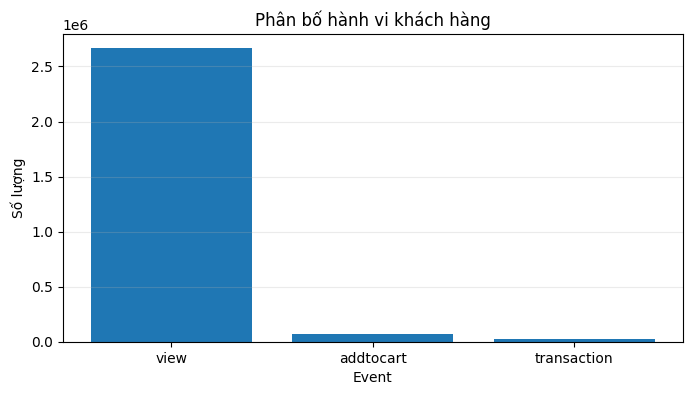

In [6]:
# 4.1. Phân bố các loại hành vi

event_counts = (
    df["event"]
    .value_counts()
    .reindex(
        ["view", "addtocart", "transaction"]
    )
    .fillna(0)
)

display(event_counts.to_frame("count"))

plt.figure(figsize=(8, 4))
plt.bar(
    event_counts.index,
    event_counts.values
)
plt.title("Phân bố hành vi khách hàng")
plt.xlabel("Event")
plt.ylabel("Số lượng")
plt.grid(axis="y", alpha=0.25)
plt.show()

,percent
event,
view,96.68
addtocart,2.50
transaction,0.81


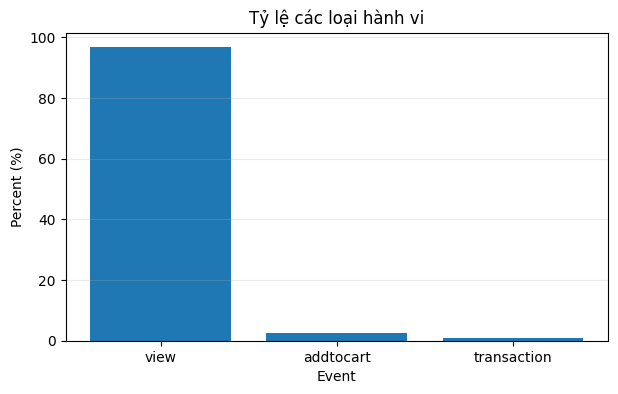

In [7]:
# 4.2. Tỷ lệ phần trăm từng hành vi

event_percent = (
    event_counts
    / event_counts.sum()
    * 100
)

display(
    event_percent
    .round(2)
    .to_frame("percent")
)

plt.figure(figsize=(7, 4))
plt.bar(
    event_percent.index,
    event_percent.values
)
plt.title("Tỷ lệ các loại hành vi")
plt.xlabel("Event")
plt.ylabel("Percent (%)")
plt.grid(axis="y", alpha=0.25)
plt.show()

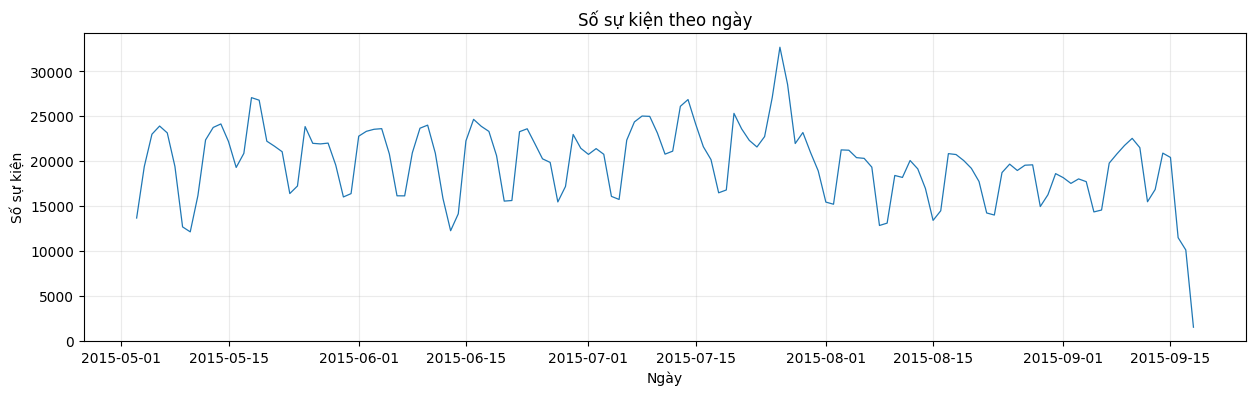

In [8]:
# 4.3. Số sự kiện theo ngày

events_per_day = (
    df.set_index("datetime")
    .resample("D")
    .size()
)

plt.figure(figsize=(15, 4))
plt.plot(
    events_per_day.index,
    events_per_day.values,
    linewidth=0.9
)
plt.title("Số sự kiện theo ngày")
plt.xlabel("Ngày")
plt.ylabel("Số sự kiện")
plt.grid(alpha=0.25)
plt.show()

Số visitor: 1407580


,events_per_visitor
count,1.407580e+06
mean,1.957715e+00
std,1.257981e+01
min,1.000000e+00
50%,1.000000e+00
75%,2.000000e+00
90%,3.000000e+00
95%,5.000000e+00
99%,1.300000e+01
max,7.757000e+03


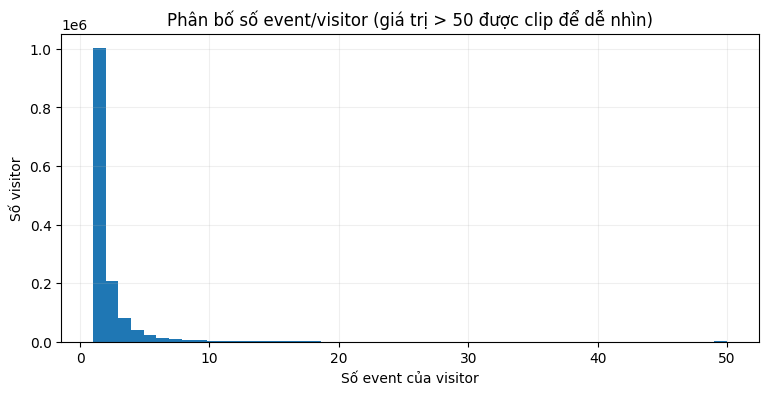

In [9]:
# 4.4. Phân bố số sự kiện trên mỗi visitor

events_per_visitor = (
    df.groupby("visitorid")
    .size()
    .sort_values(ascending=False)
)

print("Số visitor:", events_per_visitor.shape[0])

display(
    events_per_visitor
    .describe(
        percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
    )
    .to_frame("events_per_visitor")
)

plt.figure(figsize=(9, 4))
plt.hist(
    np.clip(events_per_visitor.values, 1, 50),
    bins=50
)
plt.title(
    "Phân bố số event/visitor "
    "(giá trị > 50 được clip để dễ nhìn)"
)
plt.xlabel("Số event của visitor")
plt.ylabel("Số visitor")
plt.grid(alpha=0.2)
plt.show()

,unique_visitors
event,
view,1404179
addtocart,37722
transaction,11719


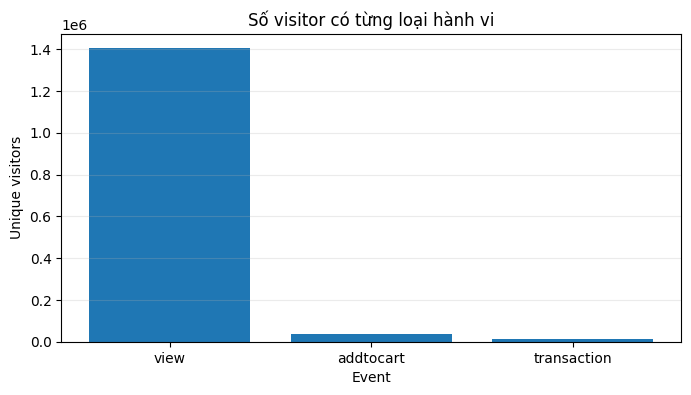

In [10]:
# 4.5. Funnel đơn giản theo số visitor từng loại hành vi

visitors_by_event = (
    df.groupby("event")["visitorid"]
    .nunique()
    .reindex(
        ["view", "addtocart", "transaction"]
    )
)

display(
    visitors_by_event
    .to_frame("unique_visitors")
)

plt.figure(figsize=(8, 4))
plt.bar(
    visitors_by_event.index,
    visitors_by_event.values
)
plt.title("Số visitor có từng loại hành vi")
plt.xlabel("Event")
plt.ylabel("Unique visitors")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 5. Phân tích chuỗi hành vi khách hàng

RNN cần một **sequence**, vì vậy ta chỉ dùng các visitor có đủ số lượng sự kiện.

Chọn:

- `SEQ_LENGTH = 5`
- cần tối thiểu `6` sự kiện để tạo được ít nhất một mẫu:
  - 5 hành vi làm input
  - hành vi thứ 6 làm target

Ví dụ:

```text
view → view → addtocart → view → view
                         ↓
                  dự đoán event tiếp theo
```

In [11]:
SEQ_LENGTH = 5
MIN_EVENTS_PER_VISITOR = SEQ_LENGTH + 1

visitor_counts = (
    df.groupby("visitorid")
    .size()
)

eligible_visitors = visitor_counts[
    visitor_counts >= MIN_EVENTS_PER_VISITOR
].index

behavior_df = df[
    df["visitorid"].isin(eligible_visitors)
].copy()

print("Tổng visitor:", df["visitorid"].nunique())
print(
    "Visitor đủ điều kiện:",
    len(eligible_visitors)
)
print(
    "Số event dùng để tạo sequence:",
    len(behavior_df)
)

Tổng visitor: 1407580
Visitor đủ điều kiện: 58627
Số event dùng để tạo sequence: 833262


In [12]:
# Xem một visitor có nhiều event để hiểu cấu trúc chuỗi

example_visitor = (
    behavior_df.groupby("visitorid")
    .size()
    .sort_values(ascending=False)
    .index[0]
)

example_sequence = (
    behavior_df[
        behavior_df["visitorid"] == example_visitor
    ][
        ["datetime", "event", "itemid"]
    ]
    .head(20)
)

print("Example visitorid:", example_visitor)
display(example_sequence)

Example visitorid: 1150086


,datetime,event,itemid
2255072,2015-06-11 14:55:17.389,view,133542
2255073,2015-06-11 15:15:35.608,view,167873
2255074,2015-06-11 15:20:06.651,view,231726
2255075,2015-06-11 15:24:48.806,view,427777
2255076,2015-06-11 15:25:32.155,view,398115
2255077,2015-06-11 15:26:43.191,addtocart,398115
2255078,2015-06-11 15:28:45.614,transaction,398115
2255079,2015-06-11 15:29:03.539,view,398115
2255080,2015-06-11 15:32:07.711,view,203425
2255081,2015-06-11 15:34:51.672,view,458489


## 6. Encoding hành vi

In [13]:
# Mã hóa 3 hành vi thành số nguyên.

EVENT_TO_ID = {
    "view": 0,
    "addtocart": 1,
    "transaction": 2
}

ID_TO_EVENT = {
    v: k for k, v in EVENT_TO_ID.items()
}

behavior_df["event_id"] = (
    behavior_df["event"]
    .map(EVENT_TO_ID)
    .astype("int32")
)

print(EVENT_TO_ID)

display(
    behavior_df[
        ["visitorid", "datetime", "event", "event_id"]
    ].head()
)

{'view': 0, 'addtocart': 1, 'transaction': 2}


,visitorid,datetime,event,event_id
4,2,2015-08-07 17:51:44.567,view,0
5,2,2015-08-07 17:53:33.790,view,0
6,2,2015-08-07 17:56:52.664,view,0
7,2,2015-08-07 18:01:08.920,view,0
8,2,2015-08-07 18:08:25.669,view,0


Ta không coi `0, 1, 2` là các giá trị có khoảng cách số học.

Trong model, lớp **Embedding** sẽ biến mỗi mã hành vi thành một vector học được trước khi đưa vào RNN.

## 7. Create Sequences theo từng visitor

In [14]:
def create_behavior_sequences(data, seq_length=5):
    """Only past events from the same visitor; exclude ambiguous timestamp ties.

    Allocate arrays once instead of keeping millions of small Python arrays alive.
    No label-dependent sampling or fitting occurs here.
    """
    if seq_length < 1:
        raise ValueError("seq_length must be positive")
    data = data.sort_values(["visitorid", "datetime"], kind="stable")
    sizes = data.groupby("visitorid", sort=False).size()
    capacity = int((sizes - seq_length).clip(lower=0).sum())
    X = np.empty((capacity, seq_length), dtype=np.int32)
    y = np.empty(capacity, dtype=np.int32)
    times = np.empty(capacity, dtype="datetime64[ns]")
    visitors = np.empty(capacity, dtype=np.int64)
    offset = 0
    for visitor, group in data.groupby("visitorid", sort=False):
        if len(group) <= seq_length:
            continue
        events = group["event_id"].to_numpy(dtype=np.int32)
        stamps = group["datetime"].to_numpy(dtype="datetime64[ns]")
        windows = np.lib.stride_tricks.sliding_window_view(events, seq_length + 1)
        valid = stamps[seq_length - 1:-1] < stamps[seq_length:]
        count = int(valid.sum())
        end = offset + count
        X[offset:end] = windows[valid, :-1]
        y[offset:end] = windows[valid, -1]
        times[offset:end] = stamps[seq_length:][valid]
        visitors[offset:end] = visitor
        offset = end
    if offset == 0:
        raise ValueError("No valid sequences: need enough strictly earlier events per visitor.")
    return X[:offset], y[:offset], pd.to_datetime(times[:offset]), visitors[:offset]

X_all, y_all, time_all, visitor_all = create_behavior_sequences(behavior_df, SEQ_LENGTH)
print("Valid sequences:", X_all.shape)
print("Events tied with the target timestamp are excluded.")

Valid sequences: (537713, 5)
Events tied with the target timestamp are excluded.


Mỗi chuỗi gồm 5 hành vi của cùng visitor, xảy ra trước thời điểm target.
Các target đồng thời với event cuối đầu vào bị loại vì không biết thứ tự thực tế.
Đây là dự đoán cho visitor có lịch sử, không phải đánh giá cold-start khách hàng mới.
Chuỗi có thể đi qua nhiều phiên truy cập; chưa sử dụng itemid hay khoảng cách thời gian.

## 8. Giới hạn số sequence để chạy nhẹ trên laptop

In [15]:
# Dataset gốc lớn. Để bài demo chạy ổn trên laptop,
# ta giới hạn số sequence nhưng vẫn lấy theo thứ tự thời gian.
#
# Có thể tăng MAX_SEQUENCES nếu máy khỏe.

MAX_SEQUENCES = 200_000

sequence_df = pd.DataFrame({
    "idx": np.arange(len(y_all)),
    "target_time": time_all,
    "target": y_all,
    "visitorid": visitor_all
})

# Sort theo target_time để giữ thứ tự thời gian
sequence_df = (
    sequence_df
    .sort_values("target_time", kind="stable")
    .reset_index(drop=True)
)

if len(sequence_df) > MAX_SEQUENCES:
    # Lấy đều trên toàn khoảng thời gian thay vì chỉ lấy đoạn đầu/cuối
    selected_pos = np.linspace(
        0,
        len(sequence_df) - 1,
        MAX_SEQUENCES,
        dtype=int
    )
    sequence_df = (
        sequence_df
        .iloc[selected_pos]
        .reset_index(drop=True)
    )

selected_idx = sequence_df["idx"].to_numpy()

X = X_all[selected_idx]
y = y_all[selected_idx]
target_times = (
    sequence_df["target_time"]
    .reset_index(drop=True)
)

print("Số sequence dùng để modeling:", len(X))
print("X shape:", X.shape)
print("y shape:", y.shape)
# Free the full arrays after selecting the modeling subset.
del X_all, y_all, time_all, visitor_all

Số sequence dùng để modeling: 200000
X shape: (200000, 5)
y shape: (200000,)


Việc giới hạn sequence chỉ nhằm mục đích **giảm thời gian train khi demo trên laptop**.  
Ta vẫn giữ dữ liệu trải đều theo toàn bộ khoảng thời gian và không làm thay đổi định nghĩa bài toán.

## 9. Train / Validation / Test Split theo thời gian

In [16]:
def temporal_split_indices(times, train_fraction=0.70, val_fraction=0.15):
    """Move boundaries before ties so equal target timestamps never cross splits."""
    if not 0 < train_fraction < 1 or not 0 < val_fraction < 1 - train_fraction:
        raise ValueError("Split fractions must be positive and leave a nonempty test fraction")
    values = np.asarray(times, dtype="datetime64[ns]")
    if len(values) < 3 or np.isnat(values).any() or (values[1:] < values[:-1]).any():
        raise ValueError("Need at least three sorted, valid target timestamps")
    train = int(len(values) * train_fraction)
    val = int(len(values) * (train_fraction + val_fraction))
    train = int(np.searchsorted(values, values[train], side="left"))
    val = int(np.searchsorted(values, values[val], side="left"))
    if not 0 < train < val < len(values):
        raise ValueError("Not enough distinct timestamps for three nonempty splits")
    return train, val

# 70% Train - 15% Validation - 15% Test
# Vì sequence_df đã sort theo target_time nên chỉ cần cắt theo index.

n = len(X)

train_end, val_end = temporal_split_indices(target_times)

X_train = X[:train_end]
y_train = y[:train_end]

X_val = X[train_end:val_end]
y_val = y[train_end:val_end]

X_test = X[val_end:]
y_test = y[val_end:]

time_train = target_times.iloc[:train_end]
time_val = target_times.iloc[train_end:val_end]
time_test = target_times.iloc[val_end:]

print("Train:", X_train.shape, y_train.shape)
print(
    time_train.min(),
    "->",
    time_train.max()
)

print("\nValidation:", X_val.shape, y_val.shape)
print(
    time_val.min(),
    "->",
    time_val.max()
)

print("\nTest:", X_test.shape, y_test.shape)
print(
    time_test.min(),
    "->",
    time_test.max()
)
assert time_train.max() < time_val.min()
assert time_val.max() < time_test.min()

Train: (140000, 5) (140000,)
2015-05-03 03:07:39.202000 -> 2015-07-31 04:09:18.795000

Validation: (30000, 5) (30000,)
2015-07-31 04:11:22.079000 -> 2015-08-24 21:44:38.617000

Test: (30000, 5) (30000,)
2015-08-24 21:46:06.192000 -> 2015-09-18 02:58:58.914000


In [17]:
# Kiểm tra phân bố nhãn ở từng tập

def class_distribution(y_arr):
    counts = pd.Series(y_arr).value_counts().sort_index()

    result = pd.DataFrame({
        "event": [
            ID_TO_EVENT.get(i, str(i))
            for i in counts.index
        ],
        "count": counts.values
    })

    result["percent"] = (
        result["count"]
        / result["count"].sum()
        * 100
    ).round(2)

    return result


print("TRAIN:")
display(class_distribution(y_train))

print("VALIDATION:")
display(class_distribution(y_val))

print("TEST:")
display(class_distribution(y_test))

TRAIN:


,event,count,percent
0,view,128981,92.13
1,addtocart,7748,5.53
2,transaction,3271,2.34


VALIDATION:


,event,count,percent
0,view,27353,91.18
1,addtocart,1882,6.27
2,transaction,765,2.55


TEST:


,event,count,percent
0,view,27466,91.55
1,addtocart,1724,5.75
2,transaction,810,2.70


## 10. Class Weight - xử lý mất cân bằng lớp

Retail behavior thường mất cân bằng mạnh: `view` nhiều hơn `addtocart` và `transaction`.

Nếu chỉ nhìn Accuracy, model có thể đoán `view` rất nhiều và vẫn có Accuracy cao.

Vì vậy ta:

- dùng **class weight** khi train
- đánh giá thêm **Macro F1**
- xem **Confusion Matrix**
- so sánh với **Majority Baseline**

In [18]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight = {
    int(cls): float(weight)
    for cls, weight
    in zip(classes, weights)
}

print("Class weight:")
for class_id, weight in class_weight.items():
    print(
        ID_TO_EVENT[class_id],
        "->",
        round(weight, 4)
    )

Class weight:
view -> 0.3618
addtocart -> 6.0231
transaction -> 14.2668


## 11. Build RNN

In [19]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

NUM_EVENTS = len(EVENT_TO_ID)
EMBED_DIM = 8
RNN_UNITS = 32

model = Sequential([
    Input(shape=(SEQ_LENGTH,)),

    Embedding(
        input_dim=NUM_EVENTS,
        output_dim=EMBED_DIM
    ),

    SimpleRNN(
        units=RNN_UNITS,
        activation="tanh"
    ),

    Dense(
        NUM_EVENTS,
        activation="softmax"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 5, 8)                │              24 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ (None, 32)                  │           1,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │              99 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,435 (5.61 KB)

 Trainable params: 1,435 (5.61 KB)

 Non-trainable params: 0 (0.00 B)

### Kiến trúc

```text
5 event IDs
     ↓
Embedding
     ↓
SimpleRNN(32)
     ↓
Dense(3, softmax)
     ↓
view / addtocart / transaction
```

Đây là bài toán **Many-to-One Classification**.

## 12. Compile

In [20]:
model.compile(
    optimizer=Adam(
        learning_rate=0.001, clipnorm=1.0
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model đã compile.")

Model đã compile.


## 13. Train

In [21]:
class ValidationMacroF1(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        predictions = self.model.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
        logs["val_macro_f1"] = f1_score(y_val, predictions, labels=[0, 1, 2],
                                        average="macro", zero_division=0)

val_sample_weight = np.array([class_weight[int(v)] for v in y_val], dtype=np.float32)
history = model.fit(
    X_train, y_train, validation_data=(X_val, y_val, val_sample_weight),
    epochs=30, batch_size=256, shuffle=True, class_weight=class_weight,
    callbacks=[ValidationMacroF1(),
               EarlyStopping(monitor="val_macro_f1", mode="max", patience=6,
                             restore_best_weights=True),
               ReduceLROnPlateau(monitor="val_macro_f1", mode="max", factor=0.5,
                                 patience=3, min_lr=1e-5)], verbose=2)
selected_config = dict(hidden_size=RNN_UNITS, embed_dim=EMBED_DIM, learning_rate=0.001)

Epoch 1/30
547/547 - 6s - 11ms/step - accuracy: 0.8161 - loss: 0.8180 - val_accuracy: 0.7994 - val_loss: 0.8028 - val_macro_f1: 0.5207 - learning_rate: 0.0010
Epoch 2/30
547/547 - 2s - 4ms/step - accuracy: 0.8147 - loss: 0.7507 - val_accuracy: 0.8000 - val_loss: 0.7814 - val_macro_f1: 0.5257 - learning_rate: 0.0010
Epoch 3/30
547/547 - 2s - 5ms/step - accuracy: 0.8135 - loss: 0.7375 - val_accuracy: 0.7974 - val_loss: 0.7728 - val_macro_f1: 0.5268 - learning_rate: 0.0010
Epoch 4/30
547/547 - 2s - 4ms/step - accuracy: 0.8120 - loss: 0.7318 - val_accuracy: 0.7974 - val_loss: 0.7683 - val_macro_f1: 0.5268 - learning_rate: 0.0010
Epoch 5/30
547/547 - 2s - 4ms/step - accuracy: 0.8110 - loss: 0.7290 - val_accuracy: 0.7973 - val_loss: 0.7655 - val_macro_f1: 0.5263 - learning_rate: 0.0010
Epoch 6/30
547/547 - 3s - 5ms/step - accuracy: 0.8106 - loss: 0.7273 - val_accuracy: 0.7973 - val_loss: 0.7636 - val_macro_f1: 0.5267 - learning_rate: 0.0010
Epoch 7/30
547/547 - 2s - 4ms/step - accuracy: 0.81

## 14. Plot Training / Validation

In [22]:
history_df = pd.DataFrame(
    history.history
)

print(
    "Số epoch đã chạy:",
    len(history_df)
)

display(history_df.tail())

Số epoch đã chạy: 10


,accuracy,loss,val_accuracy,val_loss,val_macro_f1,learning_rate
5,0.810621,0.727279,0.797333,0.763582,0.526653,0.00100
6,0.811057,0.724137,0.795700,0.758338,0.514975,0.00050
7,0.811029,0.723487,0.796433,0.757573,0.518316,0.00050
8,0.810971,0.723037,0.796433,0.756870,0.518316,0.00050
9,0.811429,0.721398,0.796467,0.756235,0.518490,0.00025


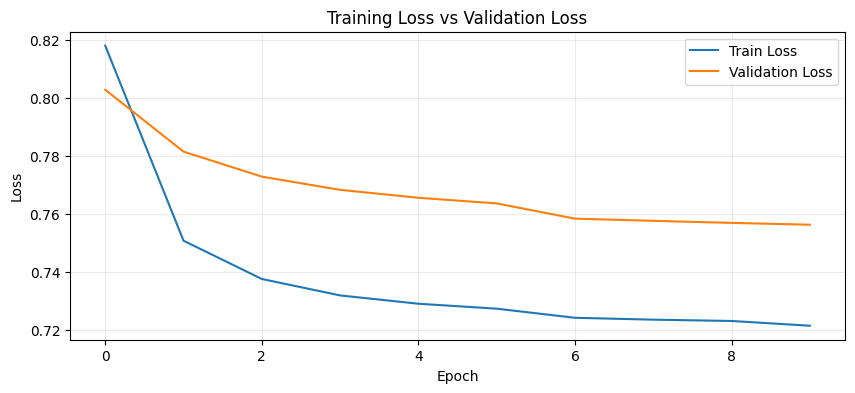

In [23]:
plt.figure(figsize=(10, 4))

plt.plot(
    history_df["loss"],
    label="Train Loss"
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

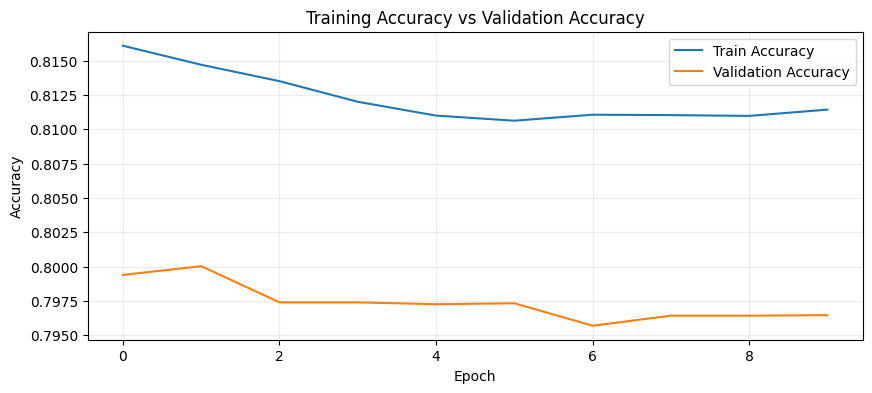

In [24]:
plt.figure(figsize=(10, 4))

plt.plot(
    history_df["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 15. Predict

In [25]:
y_prob = model.predict(
    X_test,
    verbose=0
)

y_pred = np.argmax(
    y_prob,
    axis=1
)

print("Số dự đoán:", len(y_pred))

print("\n10 nhãn thật đầu:")
print(
    [
        ID_TO_EVENT[int(i)]
        for i in y_test[:10]
    ]
)

print("\n10 nhãn dự đoán đầu:")
print(
    [
        ID_TO_EVENT[int(i)]
        for i in y_pred[:10]
    ]
)

Số dự đoán: 30000

10 nhãn thật đầu:
['view', 'view', 'view', 'transaction', 'view', 'view', 'view', 'view', 'view', 'view']

10 nhãn dự đoán đầu:
['view', 'view', 'view', 'transaction', 'addtocart', 'view', 'addtocart', 'view', 'view', 'view']


## 16. Evaluate

In [26]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(
    f"Accuracy    = {accuracy:.4f}"
)

print(
    f"Macro F1    = {macro_f1:.4f}"
)

print(
    f"Weighted F1 = {weighted_f1:.4f}"
)

Accuracy    = 0.8030
Macro F1    = 0.5263
Weighted F1 = 0.8430


### Vì sao cần Macro F1?

Dataset mất cân bằng mạnh.

`Macro F1` tính F1 cho từng lớp rồi lấy trung bình, nên lớp ít như `transaction` không bị che khuất bởi số lượng lớn `view`.

## 17. Confusion Matrix + Classification Report

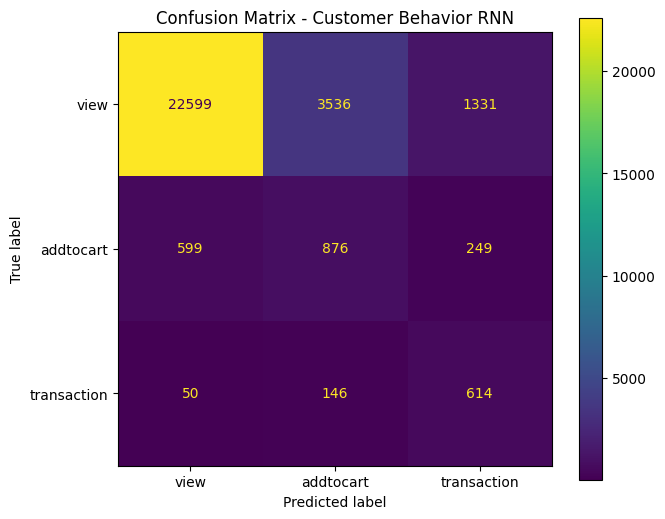

In [27]:
labels = [
    EVENT_TO_ID["view"],
    EVENT_TO_ID["addtocart"],
    EVENT_TO_ID["transaction"]
]

display_labels = [
    "view",
    "addtocart",
    "transaction"
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title("Confusion Matrix - Customer Behavior RNN")
plt.show()

In [28]:
report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=display_labels,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(
    report
).T

display(
    report_df.round(4)
)

,precision,recall,f1-score,support
view,0.9721,0.8228,0.8912,27466.000
addtocart,0.1922,0.5081,0.2789,1724.000
transaction,0.2799,0.7580,0.4088,810.000
accuracy,0.8030,0.8030,0.8030,0.803
macro avg,0.4814,0.6963,0.5263,30000.000
weighted avg,0.9086,0.8030,0.8430,30000.000


## 18. Majority Baseline

Baseline đơn giản:

> Luôn dự đoán lớp phổ biến nhất trong tập Train.

Nếu model RNN không vượt baseline hoặc Macro F1 quá thấp, cần nói rõ điều đó thay vì chỉ nhìn Accuracy.

In [29]:
def transition_baseline(X_train, y_train, X, n_classes=3, balance=False):
    """First-order Markov baseline fitted exclusively on train, with Laplace smoothing."""
    counts = np.ones((n_classes, n_classes), dtype=np.float64)
    np.add.at(counts, (X_train[:, -1], y_train), 1)
    probabilities = counts / counts.sum(axis=1, keepdims=True)
    if balance:
        frequencies = np.bincount(y_train, minlength=n_classes).clip(min=1)
        probabilities /= frequencies / frequencies.sum()
    return probabilities[X[:, -1]].argmax(axis=1)

majority_class = int(
    pd.Series(y_train)
    .value_counts()
    .idxmax()
)

baseline_pred = np.full(
    shape=len(y_test),
    fill_value=majority_class,
    dtype=np.int32
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

baseline_macro_f1 = f1_score(
    y_test,
    baseline_pred,
    average="macro",
    zero_division=0
)

comparison_df = pd.DataFrame({
    "Model": [
        "SimpleRNN",
        "Majority Baseline"
    ],
    "Accuracy": [
        accuracy,
        baseline_accuracy
    ],
    "Macro_F1": [
        macro_f1,
        baseline_macro_f1
    ]
})

display(
    comparison_df.round(4)
)
# Additional sequence-aware baselines, fitted on train only.
for name, prediction in [
    ("Last event", X_test[:, -1]),
    ("Markov", transition_baseline(X_train, y_train, X_test)),
    ("Balanced Markov", transition_baseline(X_train, y_train, X_test, balance=True)),
]:
    comparison_df.loc[len(comparison_df)] = [name, accuracy_score(y_test, prediction),
        f1_score(y_test, prediction, labels=[0, 1, 2], average="macro", zero_division=0)]
display(comparison_df.round(4))

,Model,Accuracy,Macro_F1
0,SimpleRNN,0.8030,0.5263
1,Majority Baseline,0.9155,0.3186


,Model,Accuracy,Macro_F1
0,SimpleRNN,0.8030,0.5263
1,Majority Baseline,0.9155,0.3186
2,Last event,0.8894,0.4818
3,Markov,0.9155,0.3186
4,Balanced Markov,0.8890,0.4408


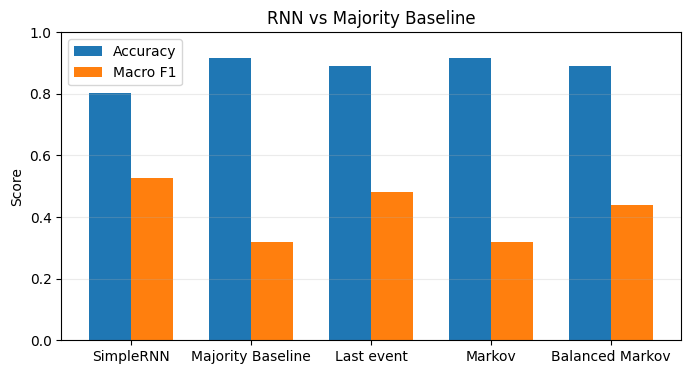

In [30]:
plt.figure(figsize=(8, 4))

x = np.arange(
    len(comparison_df)
)

width = 0.35

plt.bar(
    x - width / 2,
    comparison_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    comparison_df["Macro_F1"],
    width,
    label="Macro F1"
)

plt.xticks(
    x,
    comparison_df["Model"]
)

plt.ylim(0, 1)
plt.title("RNN vs Majority Baseline")
plt.ylabel("Score")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.show()

## 19. Visualization - Actual vs Predicted Labels

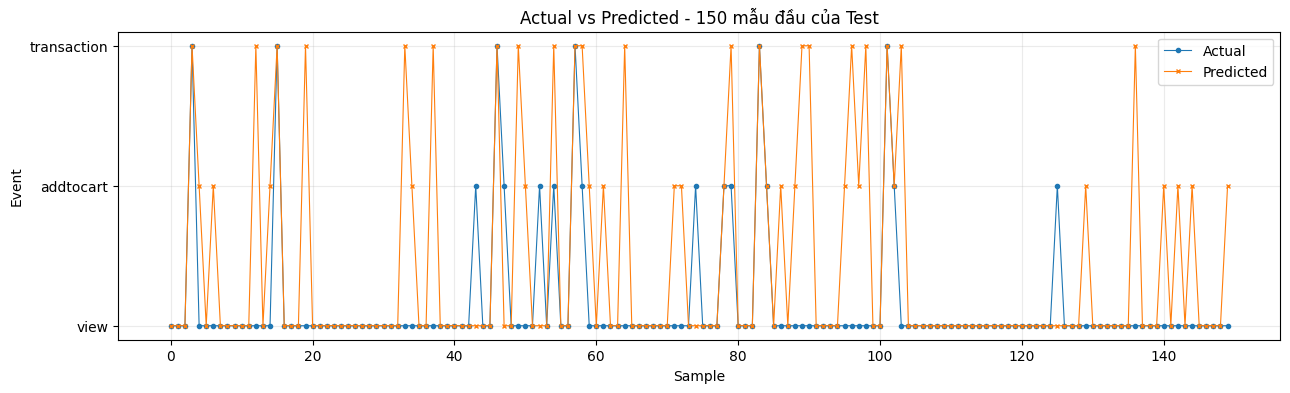

In [31]:
N_PLOT = min(
    150,
    len(y_test)
)

plt.figure(figsize=(15, 4))

plt.plot(
    np.arange(N_PLOT),
    y_test[:N_PLOT],
    marker="o",
    markersize=3,
    linewidth=0.8,
    label="Actual"
)

plt.plot(
    np.arange(N_PLOT),
    y_pred[:N_PLOT],
    marker="x",
    markersize=3,
    linewidth=0.8,
    label="Predicted"
)

plt.yticks(
    [0, 1, 2],
    [
        "view",
        "addtocart",
        "transaction"
    ]
)

plt.title(
    f"Actual vs Predicted - {N_PLOT} mẫu đầu của Test"
)

plt.xlabel("Sample")
plt.ylabel("Event")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 20. Demo dự đoán một chuỗi hành vi

In [32]:
def predict_next_event(
    event_sequence
):
    if len(event_sequence) != SEQ_LENGTH:
        raise ValueError(
            f"Cần đúng {SEQ_LENGTH} event."
        )

    encoded = np.array([
        EVENT_TO_ID[event]
        for event in event_sequence
    ], dtype=np.int32).reshape(1, -1)

    prob = model.predict(
        encoded,
        verbose=0
    )[0]

    pred_id = int(
        np.argmax(prob)
    )

    result = pd.DataFrame({
        "event": [
            ID_TO_EVENT[i]
            for i in range(NUM_EVENTS)
        ],
        "probability": prob
    }).sort_values(
        "probability",
        ascending=False
    )

    print(
        "Input:",
        " -> ".join(event_sequence)
    )

    print(
        "Predicted next event:",
        ID_TO_EVENT[pred_id]
    )

    display(
        result.reset_index(drop=True)
    )


demo_sequence = [
    "view",
    "view",
    "view",
    "addtocart",
    "view"
]

predict_next_event(
    demo_sequence
)

Input: view -> view -> view -> addtocart -> view
Predicted next event: addtocart


,event,probability
0,addtocart,0.473686
1,transaction,0.381887
2,view,0.144427


Phần demo này rất phù hợp khi thuyết trình:

```text
view → view → view → addtocart → view
                         ↓
                        RNN
                         ↓
              xác suất event tiếp theo
```

## 21. Lưu kết quả và Model

In [33]:
import hashlib
import importlib.metadata

def save_metadata(path, *, task, framework, seed, seq_length, dataset, **extra):
    digest = hashlib.sha256()
    with Path(dataset).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    versions = {}
    for name in ("numpy", "pandas", "scikit-learn", "tensorflow", "keras", "torch"):
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            pass
    metadata = dict(schema_version=1, task=task, framework=framework, seed=seed,
                    seq_length=seq_length, dataset_sha256=digest.hexdigest(),
                    package_versions=versions, **extra)
    Path(path).write_text(json.dumps(metadata, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    return metadata

test_result_df = pd.DataFrame({
    "target_time": (
        time_test
        .reset_index(drop=True)
    ),
    "actual_event": [
        ID_TO_EVENT[int(i)]
        for i in y_test
    ],
    "predicted_event": [
        ID_TO_EVENT[int(i)]
        for i in y_pred
    ],
    "prob_view": y_prob[:, EVENT_TO_ID["view"]],
    "prob_addtocart": y_prob[:, EVENT_TO_ID["addtocart"]],
    "prob_transaction": y_prob[:, EVENT_TO_ID["transaction"]]
})

prediction_path = (
    RESULTS_DIR
    / "Customer_Keras_predictions.csv"
)

test_result_df.to_csv(
    prediction_path,
    index=False
)

model_path = (
    RESULTS_DIR
    / "Customer_Keras_SimpleRNN.keras"
)

model.save(
    model_path
)

print("Đã lưu predictions:")
print(prediction_path)

print("\nĐã lưu model:")
print(model_path)

display(
    test_result_df.head()
)
metadata_extra = dict(**selected_config, selection_metric='val_macro_f1',
    train_samples=len(X_train), validation_samples=len(X_val), test_samples=len(X_test))

metadata_extra.update(architecture="embedding_simple_rnn", event_to_id=EVENT_TO_ID,
    probability_calibrated=False, strict_past_events=True,
    split_dates={"train_end": str(time_train.max()), "val_start": str(time_val.min()),
                 "val_end": str(time_val.max()), "test_start": str(time_test.min())},
    test_metrics={"accuracy": float(accuracy), "macro_f1": float(macro_f1), "weighted_f1": float(weighted_f1)})
comparison_df.to_csv(RESULTS_DIR / "Customer_Keras_metrics.csv", index=False)
report_df.to_csv(RESULTS_DIR / "Customer_Keras_classification_report.csv")

save_metadata(model_path.with_suffix(".json"), task="customer", framework="keras",
              seed=SEED, seq_length=SEQ_LENGTH, dataset=DATA_PATH, **metadata_extra)
history_df.to_csv(RESULTS_DIR / "Customer_Keras_history.csv", index=False)

Đã lưu predictions:
D:\A06\results\Customer_Keras_predictions.csv

Đã lưu model:
D:\A06\results\Customer_Keras_SimpleRNN.keras


,target_time,actual_event,predicted_event,prob_view,prob_addtocart,prob_transaction
0,2015-08-24 21:46:06.192,view,view,0.664775,0.296847,0.038378
1,2015-08-24 21:46:22.480,view,view,0.664775,0.296847,0.038378
2,2015-08-24 21:46:56.058,view,view,0.664775,0.296847,0.038378
3,2015-08-24 21:47:12.212,transaction,transaction,0.050891,0.098850,0.850259
4,2015-08-24 21:47:53.757,view,addtocart,0.144427,0.473686,0.381887


## 22. Tiêu chí chọn model và giới hạn thực nghiệm

Model được chọn theo Macro F1 trên Validation, trước khi dự đoán Test.
Train và Validation đều dùng trọng số tính từ Train cho loss.
Shuffle chỉ đổi thứ tự các cửa sổ độc lập khi train, không đổi thứ tự event trong chuỗi hay cách chia tập.
Các điểm softmax của model dùng class weight chưa được hiệu chỉnh xác suất.

In [34]:
print("Best validation Macro F1:", max(history.history["val_macro_f1"]))

Best validation Macro F1: 0.5268385206393841


## 23. Kết luận

In [35]:
print("===== KẾT QUẢ CUỐI =====")

print(
    f"Sequence length  : "
    f"{SEQ_LENGTH} event"
)

print(
    f"Train samples    : "
    f"{len(X_train):,}"
)

print(
    f"Validation       : "
    f"{len(X_val):,}"
)

print(
    f"Test samples     : "
    f"{len(X_test):,}"
)

print()

print(
    f"RNN Accuracy     : "
    f"{accuracy:.4f}"
)

print(
    f"RNN Macro F1     : "
    f"{macro_f1:.4f}"
)

print(
    f"RNN Weighted F1  : "
    f"{weighted_f1:.4f}"
)

print()

print(
    f"Baseline Accuracy: "
    f"{baseline_accuracy:.4f}"
)

print(
    f"Baseline Macro F1: "
    f"{baseline_macro_f1:.4f}"
)

===== KẾT QUẢ CUỐI =====
Sequence length  : 5 event
Train samples    : 140,000
Validation       : 30,000
Test samples     : 30,000

RNN Accuracy     : 0.8030
RNN Macro F1     : 0.5263
RNN Weighted F1  : 0.8430

Baseline Accuracy: 0.9155
Baseline Macro F1: 0.3186


### Cách diễn giải kết quả

- Mỗi mẫu dùng 5 event trước thời điểm target của cùng một visitor.
- Chia Train/Validation/Test theo thời gian; class weight chỉ tính từ Train.
- Chọn checkpoint bằng Validation Macro F1. Bản gốc trước cải tiến dùng
  validation loss, không phải chọn checkpoint bằng Test.
- Đọc Macro F1, precision/recall từng lớp và các baseline cùng với Accuracy.
- Tập Test này đã thay đổi so với bản gốc do loại target đồng thời và lấy mẫu lại.
  Không dùng chênh lệch điểm trước/sau để khẳng định model mới tốt hơn.
- Kết quả dành cho visitor có đủ lịch sử, không phải đánh giá cold-start.
- Điểm softmax sau class weighting chưa được calibration.

In [36]:
# Tải lại trực tiếp bằng framework và JSON; không cần file Python ngoài.
saved_metadata = json.loads(model_path.with_suffix(".json").read_text(encoding="utf-8"))
loaded_model = tf.keras.models.load_model(model_path, compile=False, safe_mode=True)

def predict_saved_events(event_windows):
    names = np.asarray(event_windows)
    if names.ndim == 1:
        names = names[None, :]
    if names.ndim != 2 or names.shape[1] != saved_metadata["seq_length"]:
        raise ValueError("Expected event windows with the saved sequence length")
    mapping = saved_metadata["event_to_id"]
    if any(str(event) not in mapping for event in names.flat):
        raise ValueError(f"Supported events: {list(mapping)}")
    values = np.array([[mapping[str(event)] for event in row] for row in names], dtype=np.int64)
    return loaded_model(values, training=False).numpy()

named_windows = [[ID_TO_EVENT[int(v)] for v in row] for row in X_test[:64]]
np.testing.assert_allclose(predict_saved_events(named_windows), y_prob[:64], rtol=1e-5, atol=1e-6)
print("PASS: reloaded model + label mapping reproduce test predictions.")

PASS: reloaded model + label mapping reproduce test predictions.
